# Clean Sessions

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

INPUT = Path("./inputs")  # folder containing the original files
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)

normal = pd.read_csv(INPUT / "Clean Sessions_Normal Machines.csv", low_memory=False)
returns = pd.read_csv(INPUT / "Clean Sessions_Return-Repair Machines.csv")
normal["group"] = "Normal"
returns["group"] = "Return/Repair"

combined_clean = pd.concat([normal, returns], ignore_index=True)
display(combined_clean.groupby("group").size())

group
Normal           40627
Return/Repair     6565
dtype: int64

In [3]:
profile = pd.DataFrame({
    "type": combined_clean.dtypes,
    "missing": combined_clean.isna().sum(),
    "missing_percent": (combined_clean.isna().mean() * 100).round(1),
    "unique_values": combined_clean.nunique()
})
display(profile)

datefield = "date"
parsed = pd.to_datetime(
    combined_clean[datefield].astype("string").str.replace(" UTC", "", regex=False),
    format="mixed", errors="coerce", utc=True
)
print("Unparseable non-empty dates:", (combined_clean[datefield].notna() & parsed.isna()).sum())

,type,missing,missing_percent,unique_values
anonymized_serial,str,0,0.0,216
date,str,0,0.0,35460
region,str,0,0.0,3
session_id,int64,0,0.0,11739
clean_duration,float64,2556,5.4,1615
battery_charge_start,float64,1996,4.2,23
battery_charge_end,float64,1996,4.2,23
battery_health,float64,2107,4.5,21
battery_temperature_hot,bool,0,0.0,2
battery_temperature_cold,bool,0,0.0,1


Unparseable non-empty dates: 0


In [4]:
# remove duplicate rows 
duplicates_cleanSession = combined_clean.duplicated()
print("Duplicate copies:", duplicates_cleanSession.sum())

working_cleanSession = combined_clean.drop_duplicates().copy()
print("Rows remaining:", len(working_cleanSession))
assert len(working_cleanSession) == len(combined_clean) - duplicates_cleanSession.sum()

Duplicate copies: 81
Rows remaining: 47111


In [23]:
# rows with the same group + machine + session
session_cols = ["group", "anonymized_serial", "session_id"]

repeated = working_cleanSession.duplicated(
    subset=session_cols,
    keep=False
)

repeated_sessions = working_cleanSession.loc[repeated]

columns = session_cols + ["date", "clean_duration", "battery_health"]
display(repeated_sessions[columns].sort_values(session_cols).head(10))

,group,anonymized_serial,session_id,date,clean_duration,battery_health
8819,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1432,2025-10-19 19:00:24.421102 UTC,198.0,100.0
9301,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1432,2025-10-30 12:37:03.528843 UTC,198.0,100.0
8820,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1475,2025-10-19 19:00:26.894146 UTC,245.0,100.0
8855,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1475,2025-10-30 12:37:08.844960 UTC,245.0,100.0
8850,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1478,2025-10-19 19:00:27.003432 UTC,59.0,100.0
8880,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1478,2025-10-30 12:37:08.837898 UTC,59.0,100.0
8845,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1541,2025-10-24 11:17:19.038853 UTC,330.0,100.0
8849,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1541,2025-10-30 12:37:13.692127 UTC,330.0,100.0
8828,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1562,2025-10-30 12:37:14.629612 UTC,76.0,100.0
8836,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1562,2025-10-24 11:17:19.854249 UTC,76.0,100.0


In [24]:
date_columns = ['date', 'log3_time_sync_old', 'log3_time_sync_new']
readings = working_cleanSession.drop(columns=session_cols + date_columns)
readings_columns = readings.columns

session_groups = working_cleanSession.groupby(session_cols, dropna=False)
diff_values = session_groups[readings_columns].nunique(dropna=True)
has_conflict = (diff_values > 1).any(axis=1)

print('Sessions before this check:', len(diff_values))
print('Sessions with different readings:', has_conflict.sum())
display(diff_values.loc[has_conflict].head())


Sessions before this check: 33001
Sessions with different readings: 609


region  \
group  anonymized_serial                                  session_id           
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951             1   
                                                          2756             1   
                                                          2942             1   
                                                          3077             1   
                                                          3200             1   

                                                                      clean_duration  \
group  anonymized_serial                                  session_id                   
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                     1   
                                                          2756                     2   
                                                          2942                     2   
                                                          3077                     1   
                                                          3200                     1   

                                                                      battery_charge_start  \
group  anonymized_serial                                  session_id                         
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                           1   
                                                          2756                           1   
                                                          2942                           1   
                                                          3077                           1   
                                                          3200                           1   

                                                                      battery_charge_end  \
group  anonymized_serial                                  session_id                       
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                         1   
                                                          2756                         1   
                                                          2942                         2   
                                                          3077                         1   
                                                          3200                         2   

                                                                      battery_health  \
group  anonymized_serial                                  session_id                   
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                     1   
                                                          2756                     1   
                                                          2942                     1   
                                                          3077                     1   
                                                          3200                     1   

                                                                      battery_temperature_hot  \
group  anonymized_serial                                  session_id                            
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                              1   
                                                          2756                              1   
                                                          2942                              1   
                                                          3077                              1   
                                                          3200                              1   

                                                                      battery_temperature_cold  \
group  anonymized_serial                                  session_id                             
Normal 01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2e... 1951                               1 

In [25]:
# One row per session that needs checking.
sessions_to_review = diff_values.loc[has_conflict].reset_index()
review_ids = sessions_to_review[session_cols]

# Get all original rows for those sessions.
rows_to_review = working_cleanSession.merge(
    review_ids, on=session_cols, how='inner', validate='many_to_one'
)
display(sessions_to_review.head())


,group,anonymized_serial,session_id,region,clean_duration,battery_charge_start,battery_charge_end,battery_health,battery_temperature_hot,battery_temperature_cold,battery_temperature_ok,battery_soc_state,model,running_firmware_version,ultra_fine_dust_particle_mass,fine_dust_particle_mass,coarse_dust_particle_mass,large_dust_particle_mass
0,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,1951,1,1,1,1,1,1,1,2,1,1,0,2,2,2,2
1,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,2756,1,2,1,1,1,1,1,1,1,1,0,1,1,1,1
2,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,2942,1,2,1,2,1,1,1,1,1,1,0,1,1,1,2
3,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,3077,1,1,1,1,1,1,1,1,1,1,0,1,2,2,2
4,Normal,01e45b1c61a8626425b966c61a282707bdf1fbe4edf1f2...,3200,1,1,1,2,1,1,1,2,1,1,0,3,3,3,2


In [26]:
def parse_dates(values):
    date_text = values.astype('string')
    date_text = date_text.str.replace(' UTC', '', regex=False)
    dates = pd.to_datetime(date_text, format='mixed', errors='coerce', utc=True)
    return dates


In [27]:
sessions = session_groups[readings_columns].first()
sessions = sessions.loc[~has_conflict].copy()
sessions['export_rows'] = session_groups.size()

observations = working_cleanSession[session_cols].copy()
observations['observed_at'] = parse_dates(working_cleanSession['date'])
observation_groups = observations.groupby(session_cols)['observed_at']
sessions['first_observed_at'] = observation_groups.min()
sessions['last_observed_at'] = observation_groups.max()
sessions = sessions.reset_index()

# Report choice: set aside this unexplained region label for review.
# PPE is not confirmed to mean test data.
is_ppe = sessions['region'].eq('ROW-PPE')
ppe_rows_to_review = sessions.loc[is_ppe].copy()
sessions = sessions.loc[~is_ppe].copy()
sessions['model_series'] = sessions['model'].str[:4]
display(sessions.groupby('group').size())


group
Normal           28435
Return/Repair     3956
dtype: int64

In [30]:
duration = sessions['clean_duration']
sessions['duration_eligible'] = (duration > 0) & (duration <= 3600)

health = sessions['battery_health']
sessions['health_eligible'] = health.between(0, 100)

charge_start = sessions['battery_charge_start']
charge_end = sessions['battery_charge_end']
sessions['charge_pair_eligible'] = (
    charge_start.between(0, 100)
    & charge_end.between(0, 100)
    & (charge_end <= charge_start)
)

assert not sessions.duplicated(session_cols).any()
display(sessions[['duration_eligible', 'health_eligible', 'charge_pair_eligible']].sum())

duration_eligible       30419
health_eligible         32343
charge_pair_eligible    32317
dtype: int64

group,Normal,Return/Repair
band,,
Under 1 min,34.575662,25.899865
1–5 min,35.922766,37.320704
5–10 min,16.603053,20.514208
10–60 min,12.898518,16.265223


<Axes: xlabel='Share of sessions used in this chart (%)', ylabel='band'>

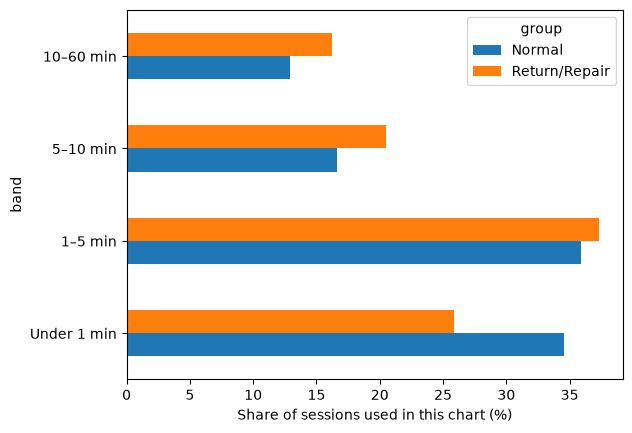

In [31]:
# sessions is the cleaned table from the notebook.
usable_sessions = sessions.loc[sessions['duration_eligible']].copy()
usable_sessions['band'] = pd.cut(
    usable_sessions['clean_duration'], [0, 60, 300, 600, 3601],
    right=False, labels=['Under 1 min', '1–5 min', '5–10 min', '10–60 min']
)
counts = pd.crosstab(usable_sessions['band'], usable_sessions['group'])
percent = counts / counts.sum() * 100
display(percent)
percent.plot.barh(xlabel='Share of sessions used in this chart (%)')

# Battery

In [5]:
normal = pd.read_csv(INPUT / "Battery_Normal Machines.csv", low_memory=False)
returns = pd.read_csv(INPUT / "Battery_Return-Repair Machines.csv")
normal["group"] = "Normal"
returns["group"] = "Return/Repair"

combined_battery = pd.concat([normal, returns], ignore_index=True)
display(combined_battery.groupby("group").size())


group
Normal            2766
Return/Repair    32614
dtype: int64

In [6]:
profile = pd.DataFrame({
    "type": combined_battery.dtypes,
    "missing": combined_battery.isna().sum(),
    "missing_percent": (combined_battery.isna().mean() * 100).round(1),
    "unique_values": combined_battery.nunique()
})
display(profile)

datefield = "hdr_timestamp"
parsed = pd.to_datetime(
    combined_battery[datefield].astype("string").str.replace(" UTC", "", regex=False),
    format="mixed", errors="coerce", utc=True
)
print("Unparseable non-empty dates:", (combined_battery[datefield].notna() & parsed.isna()).sum())

,type,missing,missing_percent,unique_values
anonymized_serial,str,0,0.0,73
server_timestamp,str,0,0.0,22033
hdr_timestamp,str,0,0.0,24082
session_id,int64,0,0.0,813
log_type,str,33549,94.8,2
log_id,float64,33549,94.8,140
decoded_data,str,33549,94.8,962
group,str,0,0.0,2


Unparseable non-empty dates: 0


In [7]:
#remove duplicate rows
duplicates_battery = combined_battery.duplicated()
print("Duplicate copies:", duplicates_battery.sum())

working_battery = combined_battery.drop_duplicates().copy()
print("Rows remaining:", len(working_battery))
assert len(working_battery) == len(combined_battery) - duplicates_battery.sum()

Duplicate copies: 6027
Rows remaining: 29353


In [39]:
print("Missing battery data:",
    working_battery["decoded_data"].isna().sum())

battery_data = working_battery.dropna(subset=["decoded_data"]).copy()

print("Rows with battery data:", len(battery_data))

Missing battery data: 27708
Rows with battery data: 1645


In [ ]:
# check one battery data row
battery_example = json.loads(
    battery_data["decoded_data"].iloc[0] # takes the first row
)

print(json.dumps(battery_example, indent=2))

{
  "header": {
    "ver_FW": "BMS_P_.00.11.001.0006",
    "ver_SW": "release - 946239b\u0000\u0000\u0000s",
    "ver_Sibyl": "sibyl.10.04.04",
    "configID": 105257482,
    "serial_HW": "00000000010AE92504048181438B2A87",
    "power_ups": 1784,
    "rated_power": 681000,
    "bpa_WIP": "FZ01U0208257208660A000628CM",
    "bpa_SNO": "720866011225H02003390N"
  },
  "eventLog": {
    "events": [
      {
        "time": 8,
        "state": 0,
        "reason": 0,
        "dischgReason": 11,
        "chargeReason": 10,
        "lockout": 0,
        "inputOutput": 32,
        "stateReason": 0,
        "cellVolt": [
          0,
          0,
          0,
          0,
          0,
          0,
          0
        ],
        "packVolt": 25170,
        "current pack": 0,
        "temp": 32767,
        "stateOfCharge": 2884,
        "runTime": 0,
        "fuelGauge": 2700,
        "stateOfHealth": 9999
      },
      {
        "time": 109,
        "state": 3,
        "reason": 16,
        "disch

# Motor

In [8]:
normal = pd.read_csv(INPUT / "Motor_Normal Machines.csv", low_memory=False)
returns = pd.read_csv(INPUT / "Motor_Return-Repair Machines.csv")
normal["group"] = "Normal"
returns["group"] = "Return/Repair"

combined_motor = pd.concat([normal, returns], ignore_index=True)
display(combined_motor.groupby("group").size())


group
Normal           470
Return/Repair    564
dtype: int64

In [9]:
profile = pd.DataFrame({
    "type": combined_motor.dtypes,
    "missing": combined_motor.isna().sum(),
    "missing_percent": (combined_motor.isna().mean() * 100).round(1),
    "unique_values": combined_motor.nunique()
})
display(profile)

datefield = "hdr_timestamp"
parsed = pd.to_datetime(
    combined_motor[datefield].astype("string").str.replace(" UTC", "", regex=False),
    format="mixed", errors="coerce", utc=True
)
print("Unparseable non-empty dates:", (combined_motor[datefield].notna() & parsed.isna()).sum())

,type,missing,missing_percent,unique_values
anonymized_serial,str,0,0.0,120
server_timestamp,str,0,0.0,1017
hdr_timestamp,str,0,0.0,962
prefix,str,564,54.5,16
model,str,0,0.0,7
...,...,...,...,...
cumulative_usage_duration_seconds,float64,564,54.5,438
group,str,0,0.0,2
region,str,470,45.5,2
log_type,str,470,45.5,1


Unparseable non-empty dates: 0


In [10]:
#remove duplicate rows
duplicates_motor = combined_motor.duplicated()
print("Duplicate copies:", duplicates_motor.sum())

working_motor = combined_motor.drop_duplicates().copy()
print("Rows remaining:", len(working_motor))
assert len(working_motor) == len(combined_motor) - duplicates_motor.sum()

Duplicate copies: 17
Rows remaining: 1017


# Faults

In [11]:
normal = pd.read_csv(INPUT / "Faults_Normal Machines.csv", low_memory=False)
returns = pd.read_csv(INPUT / "Faults_Return-Repair Machines.csv")
normal["group"] = "Normal"
returns["group"] = "Return/Repair"

combined_faults = pd.concat([normal, returns], ignore_index=True)
display(combined_faults.groupby("group").size())


group
Normal           11449
Return/Repair    19957
dtype: int64

In [12]:
profile = pd.DataFrame({
    "type": combined_faults.dtypes,
    "missing": combined_faults.isna().sum(),
    "missing_percent": (combined_faults.isna().mean() * 100).round(1),
    "unique_values": combined_faults.nunique()
})
display(profile)

datefield = "date"
parsed = pd.to_datetime(
    combined_faults[datefield].astype("string").str.replace(" UTC", "", regex=False),
    format="mixed", errors="coerce", utc=True
)
print("Unparseable non-empty dates:", (combined_faults[datefield].notna() & parsed.isna()).sum())

,type,missing,missing_percent,unique_values
anonymized_serial,str,0,0.0,176
date,str,0,0.0,2566
region,str,0,0.0,2
session_id,int64,0,0.0,2312
fault_type,int64,0,0.0,3
fault_value,int64,0,0.0,2
fault_timestamp,str,8,0.0,4523
model,str,0,0.0,8
product_alarm_source,str,3833,12.2,8
hex_error_code,str,3803,12.1,27


Unparseable non-empty dates: 0


In [13]:
#remove duplicate rows
duplicates_faults = combined_faults.duplicated()
print("Duplicate copies:", duplicates_faults.sum())

working_faults = combined_faults.drop_duplicates().copy()
print("Rows remaining:", len(working_faults))
assert len(working_faults) == len(combined_faults) - duplicates_faults.sum()

Duplicate copies: 23245
Rows remaining: 8161


In [ ]:
session_cols = ['group', 'anonymized_serial', 'session_id']
def parse_dates(values):
    date_text = values.astype('string')
    date_text = date_text.str.replace(' UTC', '', regex=False)
    dates = pd.to_datetime(date_text, format='mixed', errors='coerce', utc=True)
    return dates

In [33]:
attribute_columns = ['fault_type', 'fault_value', 'fault_timestamp']
attributes = working_faults[session_cols + attribute_columns].drop_duplicates().copy()
attributes['event_at'] = parse_dates(attributes['fault_timestamp'])

valid_batt_temperature = (attributes['fault_type'] == 11) & attributes['fault_value'].isin([0, 1, 2])
valid_airway_blockage = (attributes['fault_type'] == 12) & attributes['fault_value'].isin([0, 1, 2, 3])
valid_filter = (attributes['fault_type'] == 13) & attributes['fault_value'].isin([0, 1])
other_documented_type = attributes['fault_type'] == 7
attributes['valid_code'] = valid_batt_temperature | valid_airway_blockage | valid_filter | other_documented_type

alarm_columns = ['product_alarm_source', 'hex_error_code', 'product_alarm_fault_severity', 'fault_status']
alarms = working_faults[session_cols + alarm_columns].copy()
alarms = alarms.dropna(subset=['hex_error_code']).drop_duplicates()
print('Attributes:', len(attributes))
print('Alarm associations:', len(alarms))


Attributes: 4539
Alarm associations: 1920


In [34]:
conditions = {
    'blockage': (attributes['fault_type'] == 12) & attributes['fault_value'].isin([1, 2, 3]),
    'error_blockage': (attributes['fault_type'] == 12) & attributes['fault_value'].isin([2, 3]),
    'filter_wash': (attributes['fault_type'] == 13) & (attributes['fault_value'] == 1),
    'hot_battery': (attributes['fault_type'] == 11) & (attributes['fault_value'] == 2)
}

# Allow this cell to be rerun without creating duplicate flag columns.
sessions = sessions.drop(columns=list(conditions), errors='ignore')
rows_before = len(sessions)
for flag_name, condition in conditions.items():
    matching_keys = attributes.loc[condition & attributes['valid_code'], session_cols]
    matching_keys = matching_keys.drop_duplicates().copy()
    matching_keys[flag_name] = 1
    sessions = sessions.merge(matching_keys, on=session_cols, how='left', validate='one_to_one')
    sessions[flag_name] = sessions[flag_name].fillna(0).astype(int)

assert len(sessions) == rows_before
display(sessions.groupby('group')[list(conditions)].sum())


,blockage,error_blockage,filter_wash,hot_battery
group,,,,
Normal,408,214,1943,1
Return/Repair,147,117,243,0


In [35]:
missing_dates = attributes["event_at"].isna()

print("Fault rows without a date:", missing_dates.sum())
display(attributes.loc[missing_dates])

Fault rows without a date: 4


,group,anonymized_serial,session_id,fault_type,fault_value,fault_timestamp,event_at,valid_code
2185,Normal,bba064b50a784c1c750799892c214d92626e1ea4313a1d...,11599,12,1,NaN,NaT,True
7629,Normal,c38f7ba36adbc08256822b43d5563e33aa6e56432aab67...,5946,12,2,NaN,NaT,True
9116,Normal,b001739fc7303e40ebeb2796042b9f3895a57cac80f990...,6067,13,1,NaN,NaT,True
12970,Return/Repair,9943e64980cb0db683a700d355f6643cd1f2ee29a3d27b...,3475,12,1,NaN,NaT,True


In [36]:
fault_sessions = attributes[session_cols].drop_duplicates()

check = fault_sessions.merge(
    sessions[session_cols],
    on=session_cols,
    how="left",
    indicator=True
)

unmatched_faults = check.loc[check["_merge"] == "left_only"]

print("Fault sessions without a match:", len(unmatched_faults))
display(unmatched_faults.head())

Fault sessions without a match: 41


,group,anonymized_serial,session_id,_merge
1,Normal,917b95148f55c3f54c71534d4a349d6587981385c82d7f...,2805,left_only
23,Normal,51f8a2e3cfdbf0c9ef82c45302c3b44ce73d7ae83d7473...,7059,left_only
204,Normal,03894bbd02809bbaec1243cd8fe20c89e298a2c6ca8c82...,11851,left_only
342,Normal,1bd1761c4e0f2557e7b53c15277f4c7725b9709ee247d4...,5436,left_only
347,Normal,1bd1761c4e0f2557e7b53c15277f4c7725b9709ee247d4...,5112,left_only


,blockage,filter_wash,hot_battery
group,,,
Normal,1.43,6.83,0.0
Return/Repair,3.72,6.14,0.0


<Axes: title={'center': 'Faults: Normal vs Return/Repair'}, xlabel='Sessions with a recorded fault (%)'>

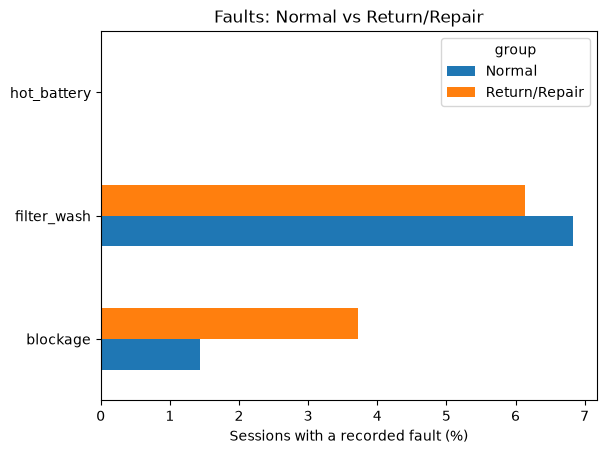

In [37]:
fault_columns = ["blockage", "filter_wash", "hot_battery"]

fault_percent = (
    sessions.groupby("group")[fault_columns].mean() * 100
)

display(fault_percent.round(2))

fault_percent.T.plot.barh(
    xlabel="Sessions with a recorded fault (%)",
    title="Faults: Normal vs Return/Repair"
)

Recorded blockage appears in 3.72% of Return/Repair sessions, compared with 1.43% of Normal sessions.

Blockage is more common in Return/Repair sessions in this dataset. 

This does not tell us whether blockage caused the machines to be returned.

In [38]:
sessions.to_csv(OUTPUT / "sessions.csv", index=False)
attributes.to_csv(OUTPUT / "fault_attributes.csv", index=False)
alarms.to_csv(OUTPUT / "alarm_associations.csv", index=False)
unmatched_faults.to_csv(OUTPUT / "unmatched_faults.csv", index=False)

In [14]:
print(working_cleanSession.shape[0])
print(working_battery.shape[0])
print(working_motor.shape[0])
print(working_faults.shape[0])

47111
29353
1017
8161
